# Tutor only: Week 2 exercise solutions

Every cell below has been run, so the outputs are the correct answers. Accept other correct approaches.

**Project scenario: Vaccine outreach review**

Dr. Kofi's district sends vaccination teams out to villages. Each row of `outreach_sessions.csv` is one outreach session in 2025.
The district health officer wants to know where the programme is working and where it's struggling. You are the analyst.

All of this data is made up.

| Column | Meaning |
|---|---|
| `session_id` | Unique ID of the session |
| `session_date` | Date of the session |
| `district`, `village` | Where it took place |
| `vaccine` | Vaccine offered |
| `team` | Outreach team |
| `children_target` | Children the team aimed to reach |
| `doses_given` | Doses actually given |
| `doses_wasted` | Doses opened but discarded (sometimes not recorded) |
| `distance_km` | Distance from the clinic |

---
## Part A · Data manipulation with pandas

### Exercise 1  *(3 marks)*

Import pandas. Load `outreach_sessions.csv` into a DataFrame called `outreach_df`. Print its shape and display the first 5 rows.

In [1]:
import pandas as pd

outreach_df = pd.read_csv("outreach_sessions.csv")
print(outreach_df.shape)
outreach_df.head()


(120, 10)


,session_id,session_date,district,village,vaccine,team,children_target,doses_given,doses_wasted,distance_km
0,S001,2025-01-06,West,Juba,Measles,Team B,106,71,7.0,21.2
1,S002,2025-01-09,South,Eko,Pentavalent,Team C,128,129,3.0,39.6
2,S003,2025-01-12,West,Imani,Measles,Team B,125,104,9.0,12.7
3,S004,2025-01-15,North,Bela,Measles,Team C,106,81,9.0,26.2
4,S005,2025-01-18,North,Bela,Pentavalent,Team C,44,40,3.0,15.3


**Note:** `read_csv` loads the file. `shape` confirms the rows and columns.

### Exercise 2  *(3 marks)*

Using position-based indexing, display the columns `session_id`, `session_date` and `district` for the rows at positions 10 to 14 (5 rows in total).

In [2]:
outreach_df.iloc[10:15, 0:3]


,session_id,session_date,district
10,S011,2025-02-05,North
11,S012,2025-02-08,South
12,S013,2025-02-11,North
13,S014,2025-02-14,North
14,S015,2025-02-17,South


**Note:** `iloc` uses positions, and the end of the range is not included, so 10:15 gives positions 10 to 14. `0:3` gives the first three columns.

### Exercise 3  *(4 marks)*

Display the sessions held in the `East` district where `doses_given` was **greater than 70**. How many are there?

In [3]:
east_busy = outreach_df[(outreach_df["district"] == "East") & (outreach_df["doses_given"] > 70)]
print(len(east_busy))
east_busy


6


,session_id,session_date,district,village,vaccine,team,children_target,doses_given,doses_wasted,distance_km
5,S006,2025-01-21,East,Gola,HPV,Team A,138,94,1.0,9.8
46,S047,2025-05-24,East,Hana,Polio,Team A,135,91,4.0,46.0
67,S068,2025-07-26,East,Hana,Polio,Team B,128,85,4.0,42.0
90,S091,2025-10-03,East,Gola,Pentavalent,Team A,157,79,1.0,27.0
111,S112,2025-12-05,East,Hana,Measles,Team A,111,81,12.0,24.5
116,S117,2025-12-20,East,Gola,Pentavalent,Team C,89,71,3.0,15.9


**Note:** Two conditions, each in round brackets, joined with `&`.

### Exercise 4  *(4 marks)*

Create a column `coverage_pct` holding `doses_given` as a percentage of `children_target`, rounded to 1 decimal place. Then display the 3 sessions with the **lowest** coverage, showing only `session_id`, `district`, `vaccine` and `coverage_pct`.

In [4]:
outreach_df["coverage_pct"] = (outreach_df["doses_given"] / outreach_df["children_target"] * 100).round(1)
outreach_df.sort_values("coverage_pct")[["session_id", "district", "vaccine", "coverage_pct"]].head(3)


,session_id,district,vaccine,coverage_pct
65,S066,North,Pentavalent,35.4
98,S099,East,HPV,37.7
74,S075,North,HPV,47.2


**Note:** Column arithmetic applies to every row at once. `sort_values` sorts from smallest to largest by default.

### Exercise 5  *(5 marks)*

Convert `session_date` to real dates and create a column `month` holding the month number. Calculate the total `doses_given` per month. Which month had the lowest total?

In [5]:
outreach_df["session_date"] = pd.to_datetime(outreach_df["session_date"])
outreach_df["month"] = outreach_df["session_date"].dt.month
monthly = outreach_df.groupby("month")["doses_given"].sum()
print("Lowest month:", monthly.idxmin(), "with", monthly.min(), "doses")
monthly


Lowest month: 2 with 530 doses


month
1     662
2     530
3     904
4     824
5     889
6     885
7     609
8     670
9     689
10    788
11    868
12    912
Name: doses_given, dtype: int64

**Note:** `.dt` only works on real dates. `idxmin` gives the label of the smallest value.

### Exercise 6  *(4 marks)*

List the mean `coverage_pct` for each `district` in **descending** order, rounded to 1 decimal place.

In [6]:
outreach_df.groupby("district")["coverage_pct"].mean().round(1).sort_values(ascending=False)


district
West     80.4
South    79.1
North    76.8
East     65.9
Name: coverage_pct, dtype: float64

**Note:** Split by district, apply the mean, combine, then sort.

### Exercise 7  *(6 marks)*

Write a function that labels a coverage value as `High` (90 or more), `Medium` (70 to less than 90) or `Low` (less than 70). Use it to create a column `coverage_level`, then count the sessions at each level.

In [7]:
def coverage_label(pct):
    if pct >= 90:
        return "High"
    elif pct >= 70:
        return "Medium"
    else:
        return "Low"

outreach_df["coverage_level"] = outreach_df["coverage_pct"].apply(coverage_label)
outreach_df["coverage_level"].value_counts()


coverage_level
Medium    58
Low       38
High      24
Name: count, dtype: int64

**Note:** `.apply` runs the function once per row. Checking the highest band first is what makes `elif` work.

### Exercise 8  *(6 marks)*

Create a report with one row per `vaccine`, showing the number of sessions, total `doses_given` and total `doses_wasted`. Add a column `wastage_pct` (wasted as a percentage of given, 1 decimal place) and sort by `wastage_pct`, highest first.

In [8]:
report = outreach_df.groupby("vaccine").agg(
    sessions=("session_id", "count"),
    given=("doses_given", "sum"),
    wasted=("doses_wasted", "sum"),
).reset_index()
report["wastage_pct"] = (report["wasted"] / report["given"] * 100).round(1)
report.sort_values("wastage_pct", ascending=False)


,vaccine,sessions,given,wasted,wastage_pct
1,Measles,42,3250,350.0,10.8
3,Polio,38,2923,150.0,5.1
2,Pentavalent,32,2472,103.0,4.2
0,HPV,8,585,14.0,2.4


**Note:** `agg` gives named results. `sum` skips the missing `doses_wasted` values, so totals are slightly understated. Good students will mention this.

### Exercise 9  *(5 marks)*

Create a DataFrame from the dictionary `{"district": ["North", "South", "East", "West"], "coordinator": ["Ada", "Ben", "Chi", "Dele"]}`. Merge it with the district means from Exercise 6 so that each district shows its coordinator. Which coordinator's district has the lowest mean coverage?

In [9]:
leads = pd.DataFrame({"district": ["North", "South", "East", "West"], "coordinator": ["Ada", "Ben", "Chi", "Dele"]})
means = outreach_df.groupby("district")["coverage_pct"].mean().round(1).reset_index()
merged = means.merge(leads, on="district").sort_values("coverage_pct")
print("Lowest:", merged.iloc[0]["coordinator"])
merged


Lowest: Chi


,district,coverage_pct,coordinator
0,East,65.9,Chi
1,North,76.8,Ada
2,South,79.1,Ben
3,West,80.4,Dele


**Note:** `reset_index` makes `district` a normal column, so `merge` can use it.

---
## Part B · Visualisation

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

outreach_df = pd.read_csv("outreach_sessions.csv")
outreach_df["coverage_pct"] = (outreach_df["doses_given"] / outreach_df["children_target"] * 100).round(1)
outreach_df["session_date"] = pd.to_datetime(outreach_df["session_date"])
outreach_df["month"] = outreach_df["session_date"].dt.month


### Exercise 1  *(5 marks)*

The officer suspects that the rainy season affects delivery. Create a **line chart with Matplotlib** of total `doses_given` per month. Give it a title, axis labels and all 12 month ticks, and start the y-axis at 0.

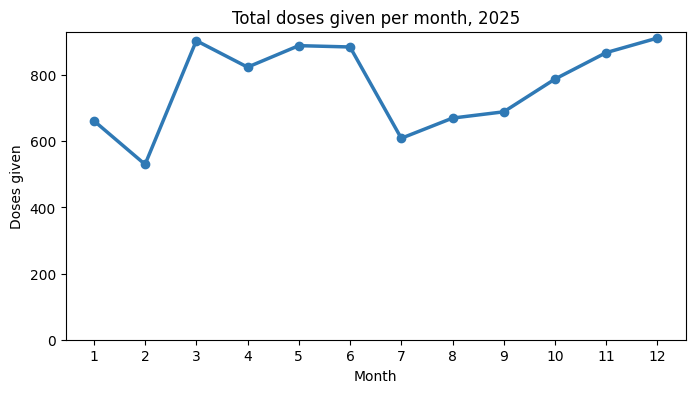

In [11]:
monthly = outreach_df.groupby("month")["doses_given"].sum()

plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly.values, color="#2F79B5", linewidth=2.5, marker="o")
plt.title("Total doses given per month, 2025")
plt.xlabel("Month")
plt.ylabel("Doses given")
plt.xticks(range(1, 13))
plt.ylim(0)
plt.show()


**Marking note:** Students should write a title stating what they see in their chart.

### Exercise 2  *(5 marks)*

Create a **sorted bar chart** of mean `coverage_pct` per district. The title must state the finding, not just the topic.

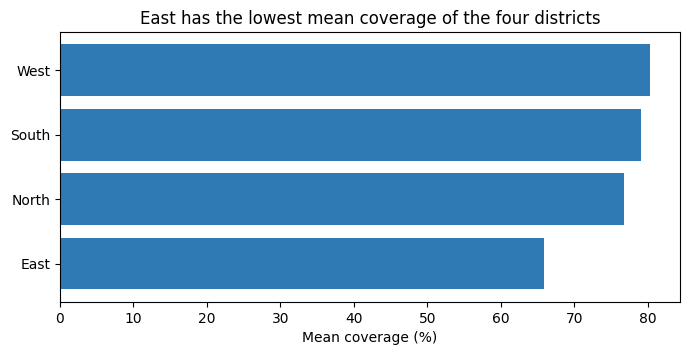

In [12]:
by_district = outreach_df.groupby("district")["coverage_pct"].mean().sort_values()

plt.figure(figsize=(8, 3.5))
plt.barh(by_district.index, by_district.values, color="#2F79B5")
plt.title("East has the lowest mean coverage of the four districts")
plt.xlabel("Mean coverage (%)")
plt.show()


**Marking note:** 1 mark is for a finding-style title. Bars must start at 0.

### Exercise 3  *(4 marks)*

Create a **histogram** of `distance_km` with 15 bins, and add a dashed vertical line at the mean.

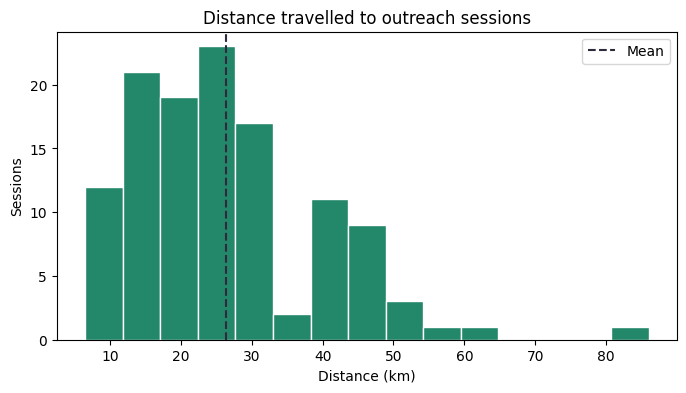

In [13]:
plt.figure(figsize=(8, 4))
plt.hist(outreach_df["distance_km"], bins=15, color="#23876A", edgecolor="white")
plt.axvline(outreach_df["distance_km"].mean(), color="#2F2A3B", linestyle="--", label="Mean")
plt.title("Distance travelled to outreach sessions")
plt.xlabel("Distance (km)")
plt.ylabel("Sessions")
plt.legend()
plt.show()


**Marking note:** `axvline` draws the mean.

### Exercise 4  *(4 marks)*

Does distance reduce coverage? Use **Seaborn** to draw a scatter plot of `distance_km` against `coverage_pct`, with `hue="district"`. In a comment, say what you conclude.

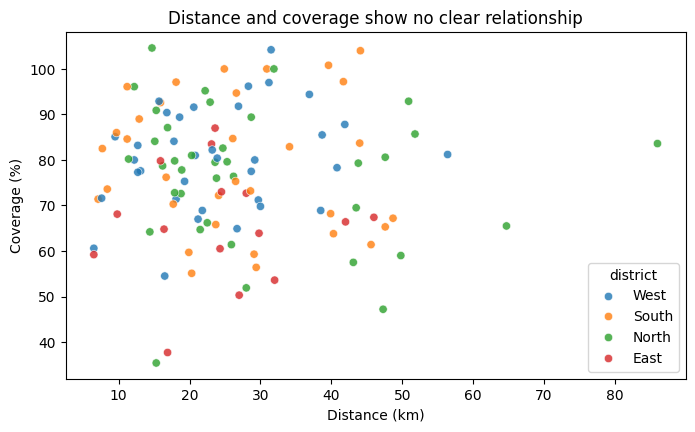

In [14]:
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=outreach_df, x="distance_km", y="coverage_pct", hue="district", alpha=0.8)
plt.title("Distance and coverage show no clear relationship")
plt.xlabel("Distance (km)")
plt.ylabel("Coverage (%)")
plt.show()
# Conclusion: no clear pattern, so distance alone does not seem to explain low coverage.


**Marking note:** Reward students who say that there is no clear relationship rather than forcing one.

### Exercise 5  *(4 marks)*

Use a **Seaborn box plot** to compare the distribution of `coverage_pct` across districts. Which district has the lowest median?

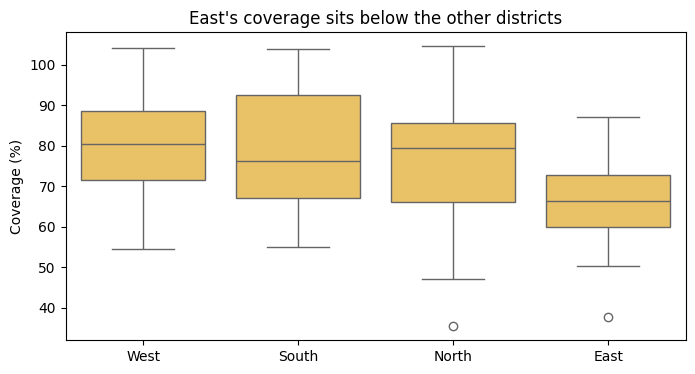

East


In [15]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=outreach_df, x="district", y="coverage_pct", color="#FFCB52")
plt.title("East's coverage sits below the other districts")
plt.xlabel("")
plt.ylabel("Coverage (%)")
plt.show()
print(outreach_df.groupby("district")["coverage_pct"].median().idxmin())


**Marking note:** The median is the line inside the box.

### Exercise 6  *(4 marks)*

Build a table of mean `coverage_pct` with `district` as rows and `vaccine` as columns. Draw it as a **heatmap** with the values written in each square.

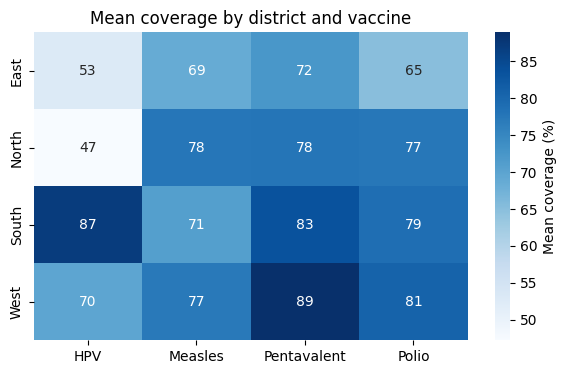

In [16]:
table = outreach_df.pivot_table(index="district", columns="vaccine", values="coverage_pct", aggfunc="mean")

plt.figure(figsize=(7, 4))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Mean coverage (%)"})
plt.title("Mean coverage by district and vaccine")
plt.xlabel("")
plt.ylabel("")
plt.show()


**Marking note:** `pivot_table` builds the grid and `annot=True` writes the numbers.

### Exercise 7  *(9 marks)*

Create a **one-page 2 × 2 report** for the officer using `plt.subplots`, reusing four charts from above. Give each chart a clear title, add an overall title with `fig.suptitle`, save it as `outreach_report.png`, and then write **one recommendation** in a comment.

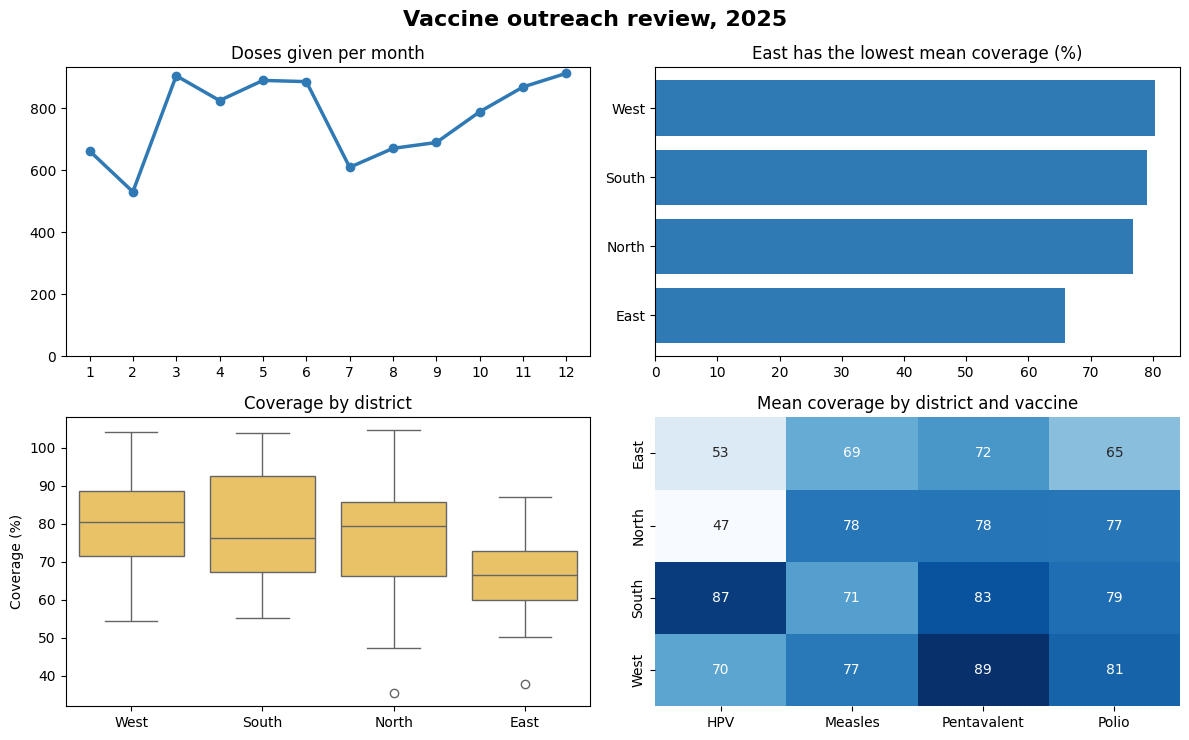

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

axes[0, 0].plot(monthly.index, monthly.values, color="#2F79B5", linewidth=2.5, marker="o")
axes[0, 0].set_title("Doses given per month")
axes[0, 0].set_xticks(range(1, 13))
axes[0, 0].set_ylim(0)

axes[0, 1].barh(by_district.index, by_district.values, color="#2F79B5")
axes[0, 1].set_title("East has the lowest mean coverage (%)")

sns.boxplot(data=outreach_df, x="district", y="coverage_pct", color="#FFCB52", ax=axes[1, 0])
axes[1, 0].set_title("Coverage by district")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Coverage (%)")

sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Mean coverage by district and vaccine")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("")

fig.suptitle("Vaccine outreach review, 2025", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("outreach_report.png", dpi=150)
plt.show()
# Recommendation: review what is holding back coverage in East, and plan extra support for it.


**Marking note:** 4 marks for four correct charts, 2 for titles and layout, 1 for saving before showing, 2 for a recommendation that follows from the charts.